# 🛰️ Goal-Oriented Time-Series Forecasting (GOTSF) — Colab 재현 노트북

**논문**: L.-A. Fechete, M. Sana, F. Ayed, N. Piovesan, W. Li, A. De Domenico, T. Si Salem,
*Goal-Oriented Time-Series Forecasting: Foundation Framework Design*, [arXiv:2504.17493](https://arxiv.org/abs/2504.17493) (2025, Huawei Paris Research Center)  
**공식 코드**: [github.com/netop-team/gotsf](https://github.com/netop-team/gotsf)

공식 저장소의 실험을 Colab에서 그대로 돌릴 수 있게 정리한 노트북입니다. 학습·평가는 **공식 코드(`script_train.py`, `script_stats.py`)를 그대로 호출**하고, Colab 환경에서 깨지는 부분만 최소한으로 패치합니다.

| 공식 저장소 | 이 노트북 | 내용 |
|---|---|---|
| `scripts/multivariate_forecasting/Wireless/train.sh {MSE\|MAE}` | **A4** 학습 | 4개 모델 × 4개 학습 정책 (5G beam 트래픽 데이터) |
| `.../Wireless/stats.sh {l} {u}` | **A5** 평가 | 관심 구간(ROI)별 평가 + interval patching |
| `.../Wireless/viz.sh` → `make_bar_plots` | **A6–A7** 결과 | ROI 4개 평균 성능 표·그래프, 예측 시각화 |
| `.../Wireless/iTransformer_train.sh` + `Synthetic_Dataset.ipynb` | **Part B** | 합성 데이터 toy 예제 (README 애니메이션) |
| 논문 Table 1 (BLW-TrafficDS, SynthDS) | **A8**, **B4** | 논문과 같은 구간으로 다시 평가하고 논문 수치와 나란히 비교 |

**기본 설정 = 논문 Table 1 조건**: MAE로 학습하고, C 정책은 논문의 C₀.₂와 저장소 설정(U₀.₁)을 모두 학습하며, toy(SynthDS)는 논문처럼 4개 모델을 모두 돌립니다. **소요 시간(추정)**: A100 기준 약 40분(무선 20개 + toy 20개 학습과 평가). T4는 학습이 몇 배 더 걸릴 수 있습니다.

> 💡 처음에는 **A3의 `RUN_MODE = "quick"`**(3 에폭)으로 전체 셀을 한 번 실행해 파이프라인을 확인한 뒤, `"full"`(논문 설정 60 에폭)로 바꿔 다시 실행하는 것을 권장합니다. quick 결과는 별도 폴더(`*_quick`)에 저장되어 섞이지 않습니다.

## 0. 런타임 확인
메뉴 **런타임 → 런타임 유형 변경 → T4 GPU**를 선택한 뒤 실행하세요.

In [1]:
import os, sys, re, json, time, shutil, subprocess
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
%matplotlib inline

gpu = subprocess.run("nvidia-smi -L", shell=True, capture_output=True, text=True).stdout.strip()
print(gpu or "⚠️ GPU가 없습니다 → CPU로 실행됩니다 (느림). 런타임 > 런타임 유형 변경 > T4 GPU 권장")
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} (CUDA={torch.cuda.is_available()}) | "
      f"numpy {np.__version__} | pandas {pd.__version__}")

GPU 0: NVIDIA RTX PRO 6000 Blackwell Server Edition (UUID: GPU-765ab57c-9d76-8f07-33e7-e2605da00fdd)
Python 3.13.15 | torch 2.11.0+cu130 (CUDA=True) | numpy 2.1.3 | pandas 2.2.3


## 1. 공식 저장소 클론 & 패키지
- 재현성을 위해 이 노트북을 검증한 커밋 `31b17e5`(2025-06-05)로 고정합니다. 최신 코드를 쓰려면 `COMMIT = None`.
- `requirements.txt`는 `torch==2.0.0`, `numpy==1.23.5`, `pandas==1.5.3`으로 고정돼 있는데, Colab(Python 3.12)에는 이 버전들을 설치할 수 없고 Colab의 CUDA용 PyTorch를 덮어쓰면 오히려 환경이 깨집니다. 그래서 **Colab 기본 패키지를 그대로 쓰고**, 코드가 import하지만 requirements에 빠져 있는 `lion-pytorch`만 `--no-deps`로 추가합니다.

In [2]:
BASE_DIR = "/content" if os.path.isdir("/content") else os.getcwd()
REPO_DIR = os.path.join(BASE_DIR, "gotsf")
COMMIT   = "31b17e55a0cb6f41bfe25230db3f81567efd58f3"

def sh(cmd, quiet=False):
    # 셸 명령 실행 (실패하면 출력과 함께 예외)
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    if r.returncode != 0:
        raise RuntimeError(f"명령 실패: {cmd}\n{out[-3000:]}")
    if out and not quiet:
        print(out)

if not os.path.isdir(os.path.join(REPO_DIR, ".git")):
    sh(f"git clone -q https://github.com/netop-team/gotsf.git {REPO_DIR}")
if COMMIT:
    sh(f"git -C {REPO_DIR} checkout -q {COMMIT}")
os.chdir(REPO_DIR)
sh("git log -1 --format='commit %h (%cd) %s' --date=short")
sh(f"{sys.executable} -m pip install -q --no-deps lion-pytorch einops", quiet=True)
print("✔ 작업 폴더:", os.getcwd())

commit 31b17e5 (2025-06-05) Update README.md
✔ 작업 폴더: /content/gotsf


## 2. Colab 호환 패치 (최소 수정)

| # | 파일 | 수정 | 이유 |
|---|---|---|---|
| 1 | `utils/tools.py` | `np.Inf` → `np.inf` | NumPy 2.x에서 `np.Inf`가 삭제되어 학습 시작 시 바로 에러 |
| 2 | `utils/tools.py` | `visual()`에서 저장 후 `plt.close()` | 평가 중 figure가 계속 쌓이는 것 방지 |
| 3 | `layers/SelfAttention_Family.py` | `reformer_pytorch` import를 try/except로 | 이번 실험에서 쓰지 않는 Reformer 때문에 생기는 의존성 제거 |
| 4 | `experiments/exp_basic.py` | GPU가 없으면 CPU 사용 | 원본은 항상 `cuda:0`을 사용 |
| 5 | `experiments/exp_long_term_forecasting_*.py` | `torch.load(..., map_location=self.device)` | GPU로 학습한 체크포인트를 CPU 세션에서도 평가 가능 |
| 6 | `data_provider/data_loader.py` | `drop(['date'], 1)` → `drop(columns=['date'])` | pandas 2.x API 변경 (`--embed`가 `timeF`가 아닐 때만 실행되는 경로) |

손실 함수, 구간 샘플링, 모델 구조, 하이퍼파라미터 등 **학습 로직은 수정하지 않습니다.** 셸 스크립트(`train.sh` 등)는 `conda activate`, `CUDA_VISIBLE_DEVICES=1`(Colab의 유일한 GPU를 가림), 16개 학습 동시 실행(`&`)을 쓰기 때문에 실행하지 않고, 같은 인자를 아래에서 Python으로 순차 실행합니다.

In [3]:
def patch(path, old, new):
    p = Path(path); s = p.read_text()
    if old in s:
        p.write_text(s.replace(old, new)); print(f"✔ 패치: {path}")
    elif new in s:
        print(f"· 이미 적용됨: {path}")
    else:
        raise RuntimeError(f"패치할 코드를 찾지 못했습니다: {path} (저장소가 바뀌었을 수 있음 → COMMIT 고정 권장)")

patch("utils/tools.py", "np.Inf", "np.inf")
patch("utils/tools.py", "plt.savefig(name, bbox_inches='tight')\n\n",
      "plt.savefig(name, bbox_inches='tight')\n    plt.close()\n\n")
patch("layers/SelfAttention_Family.py", "\nfrom reformer_pytorch import LSHSelfAttention\n",
      "\ntry:\n    from reformer_pytorch import LSHSelfAttention\nexcept ImportError:  # Reformer 계열 모델에서만 필요\n    LSHSelfAttention = None\n")
patch("experiments/exp_basic.py", "if self.args.use_gpu:", "if self.args.use_gpu and torch.cuda.is_available():")
for f in ["none", "uniform", "discrete"]:
    path = f"experiments/exp_long_term_forecasting_{f}.py"
    patch(path, "torch.load(best_model_path)", "torch.load(best_model_path, map_location=self.device)")
    patch(path, "torch.load(os.path.join(self.args.checkpoints + self.args.experiment_name, 'checkpoint.pth'))",
          "torch.load(os.path.join(self.args.checkpoints + self.args.experiment_name, 'checkpoint.pth'), map_location=self.device)")
patch("data_provider/data_loader.py", ".drop(['date'], 1)", ".drop(columns=['date'])")

chk = subprocess.run([sys.executable, "-c", "import script_stats, experiments.exp_long_term_forecasting_none, "
                      "experiments.exp_long_term_forecasting_uniform, experiments.exp_long_term_forecasting_discrete"],
                     capture_output=True, text=True)
print("✔ 공식 코드 import 확인" if chk.returncode == 0 else chk.stderr[-3000:])

✔ 패치: utils/tools.py
✔ 패치: utils/tools.py
✔ 패치: layers/SelfAttention_Family.py
✔ 패치: experiments/exp_basic.py
✔ 패치: experiments/exp_long_term_forecasting_none.py
✔ 패치: experiments/exp_long_term_forecasting_none.py
✔ 패치: experiments/exp_long_term_forecasting_uniform.py
✔ 패치: experiments/exp_long_term_forecasting_uniform.py
✔ 패치: experiments/exp_long_term_forecasting_discrete.py
✔ 패치: experiments/exp_long_term_forecasting_discrete.py
✔ 패치: data_provider/data_loader.py
✔ 공식 코드 import 확인


---
# Part A. 무선(5G beam 트래픽) 데이터 실험 — 논문의 메인 실험

## A1. 데이터 살펴보기
`dataset/wireless/wireless.csv`는 저장소에 포함되어 있습니다 (1026 시점 × 100 beams). `Dataset_Custom`이 앞에서부터 70/10/20 비율로 train/val/test를 나누고, `--scale`을 주지 않으므로 **정규화하지 않은 원래 단위**로 학습합니다. 그래서 관심 구간(ROI)을 원래 값 범위로 바로 지정할 수 있습니다. 학습 구간은 [0, 8], 평가 ROI는 이를 4등분한 [0,2], [2,4], [4,6], [6,8]입니다.

T=1026 시점 × N=100 beams | 값 범위 [0.00, 22.27]
분할(시점): train 718 / val 103 / test 205  →  윈도 샘플 수: train 599 / val 80 / test 182
test 구간 값의 ROI별 비율: [0,2] 83.1%, [2,4] 10.7%, [4,6] 3.8%, [6,8] 1.4% | 8 초과 0.9%


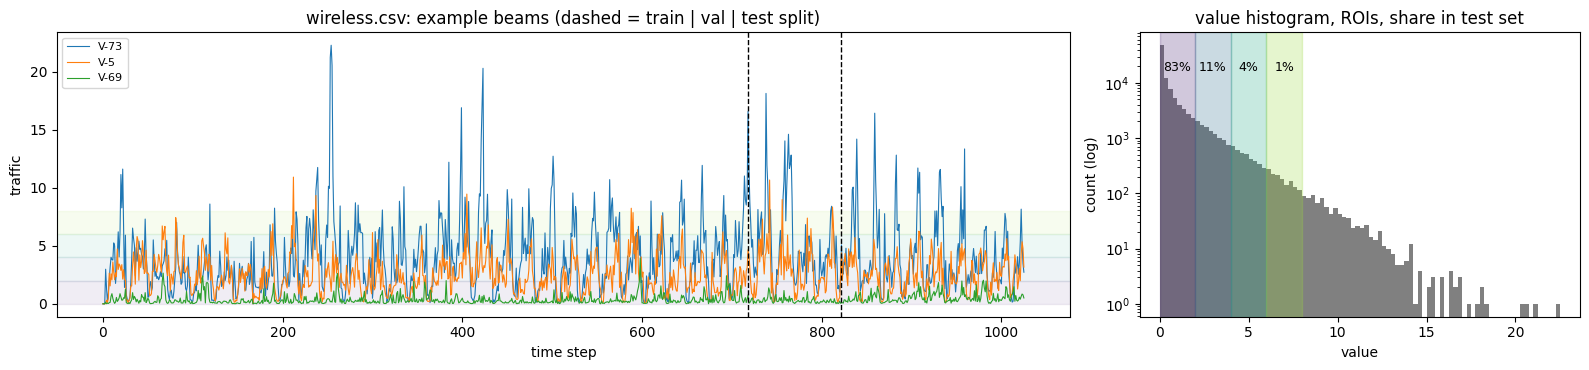

In [4]:
SEQ_LEN, PRED_LEN = 96, 24                                    # train.sh 설정
ROIS = [(0.0, 2.0), (2.0, 4.0), (4.0, 6.0), (6.0, 8.0)]       # 평가 ROI (viz.sh: [0, 8]을 4등분)

raw = pd.read_csv("dataset/wireless/wireless.csv")
names = list(raw.columns[1:])                                  # V-0 … V-98, OT (100 beams)
X = raw[names].to_numpy(dtype=float)                           # (T, N)
T, N = X.shape
n_tr, n_te = int(T * 0.7), int(T * 0.2); n_va = T - n_tr - n_te # Dataset_Custom의 70/10/20 분할
print(f"T={T} 시점 × N={N} beams | 값 범위 [{X.min():.2f}, {X.max():.2f}]")
print(f"분할(시점): train {n_tr} / val {n_va} / test {n_te}  →  윈도 샘플 수: "
      f"train {n_tr - SEQ_LEN - PRED_LEN + 1} / val {n_va - PRED_LEN + 1} / test {n_te - PRED_LEN + 1}")

test_vals = X[T - n_te:]
shares = [np.mean((test_vals >= l) & (test_vals <= u)) for l, u in ROIS]
print("test 구간 값의 ROI별 비율:", ", ".join(f"[{l:g},{u:g}] {s:.1%}" for (l, u), s in zip(ROIS, shares)),
      f"| 8 초과 {np.mean(test_vals > 8):.1%}")

roi_colors = plt.cm.viridis(np.linspace(0.1, 0.85, len(ROIS)))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw=dict(width_ratios=[2.3, 1]))
for v in np.argsort(-X.max(0))[[0, 15, 60]]:                  # 피크 크기가 다른 beam 3개
    ax1.plot(X[:, v], lw=0.8, label=names[v])
for (l, u), c in zip(ROIS, roi_colors):
    ax1.axhspan(l, u, color=c, alpha=0.08)
for b in (n_tr, n_tr + n_va):
    ax1.axvline(b, color="k", ls="--", lw=1)
ax1.set(xlabel="time step", ylabel="traffic", title="wireless.csv: example beams (dashed = train | val | test split)")
ax1.legend(loc="upper left", fontsize=8)
ax2.hist(X.ravel(), bins=np.arange(0, X.max() + 0.25, 0.25), color="gray", log=True)
for (l, u), c, s in zip(ROIS, roi_colors, shares):
    ax2.axvspan(l, u, color=c, alpha=0.25)
    ax2.text((l + u) / 2, ax2.get_ylim()[1] * 0.2, f"{s:.0%}", ha="center", fontsize=9)
ax2.set(xlabel="value", ylabel="count (log)", title="value histogram, ROIs, share in test set")
plt.tight_layout(); plt.show()

## A2. 방법 요약 (공식 코드 기준)

1. **구간 조건부 입력** — 모델에 관심 구간 $[\delta_l, \delta_u]$를 함께 넣습니다. iTransformer는 변수 토큰 2개를 추가하고, DLinear/PatchTST/TimeMixer는 입력 시퀀스 끝에 두 값을 덧붙입니다(길이 $L+2$).
2. **구간 가중 손실** — 정답 $y$가 구간에서 멀수록 손실 가중치가 줄어듭니다.
$$\mathcal{L}=\operatorname{mean}\big[\ell(\hat y, y)\, w(y)\big],\qquad w(y)=\exp\!\big(-r\cdot\max(0,\ |y-c|-h)\big),\quad c=\tfrac{\delta_l+\delta_u}{2},\ h=\tfrac{\delta_u-\delta_l}{2}$$
   여기서 $\ell$은 MSE 또는 MAE, $r$은 `decay_rate`입니다.
3. **학습 정책**
   - **B** (`none`): 일반 학습, 구간 조건 없음.
   - **C** (`uniform`): 배치의 샘플마다 [0, 8] 안에서 최소 폭 $\hat w\cdot 8=0.8$인 구간을 무작위로 뽑음. $r=10^{10}$이라 사실상 0/1 마스크. 논문 Table 1의 C₀.₂는 $\hat w=0.2$(최소 폭 1.6)이며 `uniform02`로 함께 학습합니다.
   - **D** (`discrete4`, `discrete8`): [0, 8]을 L개의 같은 폭 sub-interval로 나누고 샘플마다 하나를 뽑음, $r=37$. 출력 길이를 두 배로 늘려 **구간 분류 헤드** $p(y\in[\delta_l,\delta_u])$도 함께 학습합니다(BCE, 가중치 `cls_weight=0.1`). 주의: `train.sh`에서 `discrete4`는 L=8, `discrete8`은 L=16입니다.
4. **추론 시 patching (D 정책)** — ROI가 여러 sub-interval에 걸치면 각 sub-interval로 조건을 준 예측을 모은 뒤, 시점·변수마다 분류 확률이 가장 큰 예측을 고르거나(`max`) 확률 가중 평균을 냅니다(`expectation`, $\hat y=\sum_k p_k\hat y_k/\sum_k p_k$).
5. **평가 지표** — 정답이 ROI 안에 있는 위치만 남기는 마스크를 예측과 정답에 곱한 뒤 전체 원소에 대해 MAE/MSE를 계산합니다(`mask = (true >= l) & (true <= u)`). 드문 ROI일수록 값 자체가 작게 나오므로 **같은 ROI 안에서 정책끼리** 비교하세요.

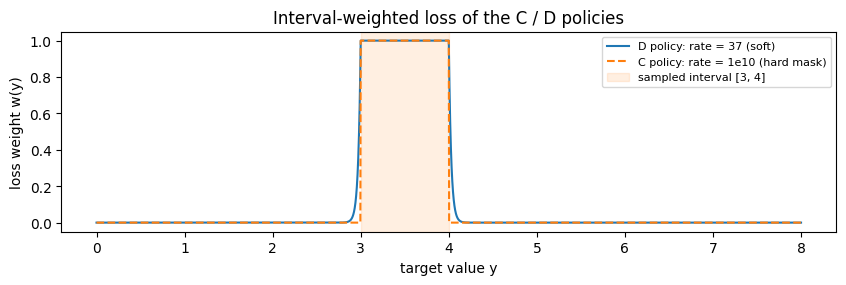

In [5]:
def interval_weight(y, l, u, rate):   # exp_long_term_forecasting_{uniform,discrete}.py의 decay_function과 동일
    return np.exp(-rate * np.maximum(0.0, np.abs(y - (l + u) / 2) - (u - l) / 2))

y = np.linspace(0, 8, 2001)
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.plot(y, interval_weight(y, 3, 4, 37), label="D policy: rate = 37 (soft)")
ax.plot(y, interval_weight(y, 3, 4, 1e10), "--", label="C policy: rate = 1e10 (hard mask)")
ax.axvspan(3, 4, color="tab:orange", alpha=0.12, label="sampled interval [3, 4]")
ax.set(xlabel="target value y", ylabel="loss weight w(y)", title="Interval-weighted loss of the C / D policies")
ax.legend(loc="upper right", fontsize=8); plt.show()

## A3. 실험 설정 (`train.sh` + 논문 Table 1 조건)

| 항목 | 값 |
|---|---|
| 입력 / 예측 길이 | `seq_len=96`, `pred_len=24` |
| 모델 크기 | `e_layers=2`, `d_model=128`, `d_ff=128`, `n_heads=4`, `dropout=0.1` |
| 최적화 | Adam, `learning_rate=1e-4`, cosine(`lradj=type3`), `batch_size=32`, `train_epochs=60` |
| 학습 구간 | `train_interval_l=0`, `train_interval_u=8` |
| C 정책 | `w_hat=0.1` (`train.sh`, `uniform`) + `w_hat=0.2` (논문 C₀.₂, `uniform02`) |
| D 정책 | `decay_rate=37`, `nr_intervals=8` (`discrete4`) / `16` (`discrete8`), `cls_weight=0.1` |

원본과 다른 점은 `num_workers=0`(검증 때마다 워커 10개를 새로 띄우는 비용이 데이터 로딩보다 커서 0이 훨씬 빠름, 결과에는 영향 없음)과 **순차 실행**뿐입니다.

논문 부록의 학습 설정(3층, `d_model=256`, AdamW `lr=1e-3`, 50 에폭, patience 5)은 `train.sh`와 다르지만, `train.sh` 설정으로 학습한 B 정책이 논문 Table 1과 구간별로 0.2(×10⁻³) 이내로 일치해서 `train.sh`를 따릅니다. 기본값은 논문 표와 같은 **MAE 학습**이고, 저장소 `viz.sh` 결과(MSE+MAE)까지 재현하려면 `LOSSES = ["MSE", "MAE"]`로 바꾸세요.

In [6]:
RUN_MODE     = "full"           # "quick": 3 에폭으로 파이프라인 점검 | "full": 논문 설정 (60 에폭)
LOSSES       = ["MAE"]          # 논문 Table 1은 MAE 학습. 저장소 viz.sh 전체 재현은 ["MSE", "MAE"]
MODELS       = ["iTransformer", "DLinear", "PatchTST", "TimeMixer"]
POLICIES     = ["none", "uniform", "uniform02", "discrete4", "discrete8"]   # uniform02 = 논문 C_0.2
SKIP_IF_DONE = True             # 이미 학습·평가한 실험은 건너뜀 (세션이 끊긴 뒤 이어서 실행할 때 유용)

EPOCHS   = {"full": 60, "quick": 3}[RUN_MODE]
TAG      = "" if RUN_MODE == "full" else "_quick"
CKPT_DIR, RES_DIR, OUT_DIR, LOG_DIR = f"./checkpoints{TAG}/", f"./results{TAG}/", f"./outputs{TAG}/", "./logs/"
for d in (OUT_DIR, LOG_DIR):
    os.makedirs(d, exist_ok=True)

COMMON = dict(root_path="./dataset/wireless/", data_path="wireless.csv", data="custom", features="M",
              seq_len=96, pred_len=24, e_layers=2, enc_in=100, dec_in=100, c_out=100, des="Exp",
              d_model=128, d_ff=128, itr=1, n_heads=4, batch_size=32, lradj="type3", learning_rate=1e-4,
              dropout=0.1, num_workers=0, checkpoints=CKPT_DIR, results=RES_DIR)
POLICY_ARGS = {
    "none":      dict(model_id="None", training_interval_technique="interval-none"),
    "uniform":   dict(model_id="Uniform", training_interval_technique="interval-uniform",
                      w_hat=0.1, train_interval_l=0, train_interval_u=8),
    "uniform02": dict(model_id="Uniform", training_interval_technique="interval-uniform",      # 논문 Table 1의 C_0.2
                      w_hat=0.2, train_interval_l=0, train_interval_u=8),
    "discrete4": dict(model_id="Discrete", training_interval_technique="interval-discrete",
                      decay_rate=37, nr_intervals=8, train_interval_l=0, train_interval_u=8),
    "discrete8": dict(model_id="Discrete", training_interval_technique="interval-discrete",
                      decay_rate=37, nr_intervals=16, train_interval_l=0, train_interval_u=8),
}

def exp_name(model, policy, loss):                 # train.sh의 --experiment_name 규칙
    return f"{model}_{policy}_{loss}"

def wireless_args(model, policy, loss):
    return dict(COMMON, **POLICY_ARGS[policy], model=model, experiment_name=exp_name(model, policy, loss),
                train_epochs=EPOCHS, loss=loss)

print(f"모드 {RUN_MODE} | 에폭 {EPOCHS} | 학습 {len(LOSSES) * len(MODELS) * len(POLICIES)}개 | 저장 위치 {CKPT_DIR}, {RES_DIR}")

모드 full | 에폭 60 | 학습 20개 | 저장 위치 ./checkpoints/, ./results/


### (선택) Google Drive에 저장
Colab 세션이 끊겨도 학습 결과를 유지하려면 `USE_DRIVE = True`로 바꿔 실행하세요. 체크포인트·결과·로그 폴더가 Drive로 연결되고, 다시 실행하면 `SKIP_IF_DONE` 덕분에 끝난 실험은 건너뜁니다. 예측 배열까지 저장되므로 손실 함수 1개당 약 1GB를 차지합니다.

In [7]:
USE_DRIVE = False
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = "/content/drive/MyDrive/gotsf_colab"
    for d in (CKPT_DIR, RES_DIR, OUT_DIR, LOG_DIR):
        local = os.path.normpath(d)
        target = os.path.join(DRIVE_ROOT, local)
        os.makedirs(target, exist_ok=True)
        if os.path.islink(local):
            continue
        if os.path.isdir(local):                       # 이미 로컬에 있던 결과는 Drive로 옮김
            shutil.copytree(local, target, dirs_exist_ok=True); shutil.rmtree(local)
        os.symlink(target, local)
    print("✔ Drive에 저장:", DRIVE_ROOT)

## A4. 학습 (`train.sh` 재현)
각 실험은 `script_train.py`를 별도 프로세스로 실행합니다. 진행 막대는 끄고 10 에폭마다 손실만 출력하며, 전체 로그는 `logs/`에 남습니다. 체크포인트는 `checkpoints/<모델>_<정책>_<손실>/`에 저장됩니다.

In [8]:
SUB_ENV = dict(os.environ, TQDM_DISABLE="1", PYTHONWARNINGS="ignore", MPLBACKEND="Agg")

def run_train(args, ckpt_dir, tag=""):
    name, epochs = args["experiment_name"], int(args["train_epochs"])
    if SKIP_IF_DONE and os.path.exists(os.path.join(ckpt_dir, name, "train_loss.npy")):
        print(f"⏭  {name}: 이미 학습됨 → 건너뜀"); return
    os.makedirs(LOG_DIR, exist_ok=True)
    log_path = os.path.join(LOG_DIR, f"train_{name}{tag}.log")
    cmd = [sys.executable, "-u", "script_train.py"] + [x for k, v in args.items() for x in (f"--{k}", str(v))]
    t0, last, shown = time.time(), None, set()
    with open(log_path, "w", buffering=1) as log:          # 줄 단위로 바로 기록 → 학습 중에도 로그 확인 가능
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=SUB_ENV)
        for line in p.stdout:
            log.write(line)
            m = re.match(r"Epoch: (\d+), Steps: \d+ \| (.*)", line)
            if m:
                ep, last = int(m.group(1)), (int(m.group(1)), m.group(2).strip())
                if ep == 1 or ep % 10 == 0 or ep == epochs:
                    print(f"    ep {ep:>3}/{epochs} | {last[1]}"); shown.add(ep)
            elif line.startswith("Early stopping"):
                print("    early stopping")
        p.wait()
    if p.returncode != 0:
        print("".join(open(log_path).readlines()[-30:]))
        raise RuntimeError(f"{name} 학습 실패 → 로그: {log_path}")
    if last and last[0] not in shown:
        print(f"    ep {last[0]:>3}/{epochs} | {last[1]}")
    print(f"✅ {name} ({time.time() - t0:.0f}s)")

In [9]:
jobs = [(m, p, l) for l in LOSSES for m in MODELS for p in POLICIES]
t_all = time.time()
for i, (model, policy, loss) in enumerate(jobs, 1):
    print(f"▶ [{i}/{len(jobs)}] {exp_name(model, policy, loss)}")
    run_train(wireless_args(model, policy, loss), CKPT_DIR, TAG)
print(f"\n학습 완료: {(time.time() - t_all) / 60:.1f}분")

▶ [1/20] iTransformer_none_MAE
    ep   1/60 | Train Loss: 0.6840456 Vali Loss: 0.6603184 Test Loss: 0.6165206
    ep  10/60 | Train Loss: 0.4861599 Vali Loss: 0.5065411 Test Loss: 0.4650197
    ep  20/60 | Train Loss: 0.4679585 Vali Loss: 0.4889268 Test Loss: 0.4498003
    ep  30/60 | Train Loss: 0.4610811 Vali Loss: 0.4820159 Test Loss: 0.4444890
    ep  40/60 | Train Loss: 0.4577600 Vali Loss: 0.4790014 Test Loss: 0.4423204
    ep  50/60 | Train Loss: 0.4557992 Vali Loss: 0.4774227 Test Loss: 0.4413991
    ep  60/60 | Train Loss: 0.4551917 Vali Loss: 0.4768301 Test Loss: 0.4409956
✅ iTransformer_none_MAE (15s)
▶ [2/20] iTransformer_uniform_MAE
    ep   1/60 | Train Loss: 0.1315256 Vali Loss: 0.1603448 Test Loss: 0.1549337
    ep  10/60 | Train Loss: 0.1023798 Vali Loss: 0.1148291 Test Loss: 0.1102224
    ep  20/60 | Train Loss: 0.1021288 Vali Loss: 0.1061906 Test Loss: 0.1021031
    ep  30/60 | Train Loss: 0.0947714 Vali Loss: 0.1024608 Test Loss: 0.0989418
    ep  40/60 | Train Los

## A5. 평가 (`stats.sh` 재현)
공식 `script_stats.ModelEvaluator`를 그대로 쓰되, `stats.sh`처럼 실험×ROI마다 새 프로세스를 띄우지 않고 한 프로세스에서 처리합니다.

- **B, C 정책**: ROI마다 `run_experiment_none_uniform()` 호출. C 모델은 ROI로 조건을 주고, B 모델은 조건 없이 예측한 뒤 ROI 마스크로 평가합니다.
- **D 정책**: `run_experiment_discrete()`로 학습한 sub-interval마다 조건부 예측과 분류 확률을 저장하고, ROI마다 `patch_experiments_discrete()`를 `expectation`, `max` 순서로 호출합니다.

결과는 `results/<실험명>/(l, u){_max|_expectation}/metrics.npy`(`[mae, mse, rmse, mape, mspe]`)에 저장됩니다. 공식 patching 코드는 순수 Python 루프라 실험당 수십 초가 걸립니다.

In [10]:
EVAL_SCRIPT = '''
# stats.sh와 같은 평가를 한 프로세스에서 수행 (공식 script_stats.ModelEvaluator 사용)
import argparse, json, os, random, sys, time
import numpy as np, torch
sys.path.insert(0, os.getcwd())
from script_stats import ModelEvaluator

p = argparse.ArgumentParser()
p.add_argument("--experiments", nargs="+", required=True)
p.add_argument("--rois", required=True)
p.add_argument("--checkpoints_dir", default="checkpoints")
p.add_argument("--results_dir", default="results")
a = p.parse_args()
rois = [(float(l), float(u)) for l, u in json.loads(a.rois)]

for name in a.experiments:
    t0 = time.time()
    random.seed(2023); np.random.seed(2023); torch.manual_seed(2023)      # script_stats.py와 같은 시드
    ev = ModelEvaluator(argparse.Namespace(
        experiment_name=name, eval_interval_l=0.0, eval_interval_u=0.0, eval_on_train=False, strategy="max",
        checkpoints_dir=a.checkpoints_dir, results_dir=a.results_dir, use_multi_gpu=False, use_gpu=True))
    if ev.model_args.training_interval_technique == "interval-discrete":
        ev.run_experiment_discrete()
        for l, u in rois:
            for strategy in ("expectation", "max"):      # max를 나중에 → "(l, u)/" 폴더 = max 결과 (viz.sh 규칙)
                ev.args.eval_interval_l, ev.args.eval_interval_u, ev.args.strategy = l, u, strategy
                ev.patch_experiments_discrete()
    else:
        for l, u in rois:
            ev.args.eval_interval_l, ev.args.eval_interval_u = l, u
            ev.run_experiment_none_uniform()
    del ev
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"[eval] {name} ({time.time() - t0:.0f}s)", flush=True)
'''
Path("colab_eval.py").write_text(EVAL_SCRIPT)

def separate_interval(interval, nr_intervals):
    # utils.tools.separate_interval과 동일 (그 모듈은 import할 때 matplotlib 백엔드를 바꿔서 복사해 둠)
    out, eps = [], (interval[1] - interval[0]) / nr_intervals
    d1, d2 = interval[0], interval[0] + eps
    for _ in range(nr_intervals):
        out.append((d1, d2)); d1, d2 = d1 + eps, d2 + eps
    return out

def load_metric(res_dir, name, roi, suffix, idx):
    # results/<실험>/(l, u)<suffix>/metrics.npy = [mae, mse, rmse, mape, mspe]
    f = os.path.join(res_dir, name, f"({roi[0]}, {roi[1]}){suffix}", "metrics.npy")
    return float(np.load(f)[idx]) if os.path.exists(f) else np.nan

def eval_done(name, policy, rois, ckpt_dir, res_dir):
    ckpt = os.path.join(ckpt_dir, name, "checkpoint.pth")
    sufs = ["_max", "_expectation"] if policy.startswith("discrete") else [""]
    files = [os.path.join(res_dir, name, f"({l}, {u}){s}", "metrics.npy") for l, u in rois for s in sufs]
    return all(os.path.exists(f) and os.path.getmtime(f) >= os.path.getmtime(ckpt) for f in files)

def run_eval(todo, rois, ckpt_dir, res_dir, tag=""):
    # todo: [(실험명, 정책)]
    names = [n for n, pol in todo if os.path.exists(os.path.join(ckpt_dir, n, "checkpoint.pth"))
             and not (SKIP_IF_DONE and eval_done(n, pol, rois, ckpt_dir, res_dir))]
    print(f"평가할 실험 {len(names)}개 (전체 {len(todo)}개 중)")
    if not names:
        return
    os.makedirs(LOG_DIR, exist_ok=True)
    log_path = os.path.join(LOG_DIR, f"eval{tag}.log")
    cmd = [sys.executable, "-u", "colab_eval.py", "--experiments", *names, "--rois", json.dumps(rois),
           "--checkpoints_dir", ckpt_dir, "--results_dir", res_dir]
    with open(log_path, "a", buffering=1) as log:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=SUB_ENV)
        for line in p.stdout:
            log.write(line)
            if line.startswith("[eval]"):
                print("  ✅", line[7:].rstrip())
        p.wait()
    if p.returncode != 0:
        print("".join(open(log_path).readlines()[-30:]))
        raise RuntimeError(f"평가 실패 → 로그: {log_path}")

# ── 논문 Table 1과 비교하는 도구 (A8, B4에서 사용) ───────────────────────
PAPER_POLICIES = ["D_L", "D¹_2L", "D∞_2L", "B", "C_0.2"]     # 논문 Table 1의 열 순서
EXTRA_POLICY = "C_0.1 (저장소)"                                 # 저장소 스크립트의 w_hat=0.1 (논문 표에는 없음)

def policy_spec(name_of):
    # 논문 열 → (실험명, 결과 폴더 접미사). name_of(policy)는 실험명을 돌려주는 함수
    return {"D_L": (name_of("discrete4"), "_max"), "D¹_2L": (name_of("discrete8"), "_expectation"),
            "D∞_2L": (name_of("discrete8"), "_max"), "B": (name_of("none"), ""), "C_0.2": (name_of("uniform02"), ""),
            EXTRA_POLICY: (name_of("uniform"), "")}

def interval_table(spec, rois, avg_name):
    # 구간별 마스크 MAE ×10³ (논문 표와 같은 지표) + 평균 행
    df = pd.DataFrame({lab: [load_metric(RES_DIR, n, r, suf, 0) * 1e3 for r in rois] for lab, (n, suf) in spec.items()},
                      index=[f"I{k + 1}" for k in range(len(rois))])
    df.loc[avg_name] = df.mean()
    return df

def paper_table(rows, avg_name):
    df = pd.DataFrame(rows, index=[f"I{k + 1}" for k in range(len(rows))], columns=PAPER_POLICIES)
    df.loc[avg_name] = df.mean()
    return df

def improvement(df):
    # 논문 방식: B 대비 가장 좋은 정책의 개선율 (B가 가장 좋으면 0%)
    others = [c for c in PAPER_POLICIES if c != "B"]
    return ((df["B"] - df[others].min(axis=1)) / df["B"] * 100).clip(lower=0)

def compare_summary(pairs, avg_name, caption):
    # pairs: {(학습 손실, 모델): (재현 표, 논문 표)} → 평균 행을 재현/논문 나란히
    cols = [(c, w) for c in PAPER_POLICIES for w in ("재현", "논문")] + [(EXTRA_POLICY, "재현")]
    rows = [[(ours if w == "재현" else paper).loc[avg_name, c] for c, w in cols]
            + [improvement(ours)[avg_name], improvement(paper)[avg_name]] for ours, paper in pairs.values()]
    df = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(list(pairs), names=["학습 손실", "모델"]),
                      columns=pd.MultiIndex.from_tuples(cols + [("개선율 %", "재현"), ("개선율 %", "논문")]))
    display(df.style.format("{:.1f}", na_rep="-").set_caption(caption))
    return df

def plot_vs_paper(pairs, title, fname):
    mt = {"D_L": r"$D_L$", "D¹_2L": r"$D^1_{2L}$", "D∞_2L": r"$D^\infty_{2L}$", "B": "B", "C_0.2": r"$C_{0.2}$"}
    colors = dict(zip(PAPER_POLICIES, ["#DD8452", "#8C8C3C", "#C44E52", "#4C72B0", "#55A868"]))
    fig, axes = plt.subplots(1, len(pairs), figsize=(4.3 * len(pairs), 3.9), squeeze=False, sharey=True)
    for ax, ((loss, model), (ours, paper)) in zip(axes[0], pairs.items()):
        xs = [ix for ix in ours.index if "–" not in ix]
        for c in PAPER_POLICIES:
            ax.plot(xs, ours.loc[xs, c], color=colors[c], marker="o", ms=3.5, lw=1.6, label=mt[c])
            ax.plot(xs, paper.loc[xs, c], color=colors[c], ls="--", lw=1, alpha=0.8)
        ax.set(yscale="log", title=f"{model} ({loss} loss)", xlabel="interval")
    axes[0][0].set_ylabel("masked MAE x1e3 (log)")
    axes[0][-1].legend(fontsize=7, title="solid = ours, dashed = paper", title_fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, fname), dpi=150); plt.show()

In [11]:
t0 = time.time()
run_eval([(exp_name(m, p, l), p) for l in LOSSES for m in MODELS for p in POLICIES], ROIS, CKPT_DIR, RES_DIR, TAG)
print(f"평가 완료: {(time.time() - t0) / 60:.1f}분")

평가할 실험 20개 (전체 20개 중)
  ✅ iTransformer_none_MAE (1s)
  ✅ iTransformer_uniform_MAE (0s)
  ✅ iTransformer_uniform02_MAE (0s)
  ✅ iTransformer_discrete4_MAE (14s)
  ✅ iTransformer_discrete8_MAE (20s)
  ✅ DLinear_none_MAE (0s)
  ✅ DLinear_uniform_MAE (0s)
  ✅ DLinear_uniform02_MAE (0s)
  ✅ DLinear_discrete4_MAE (14s)
  ✅ DLinear_discrete8_MAE (20s)
  ✅ PatchTST_none_MAE (0s)
  ✅ PatchTST_uniform_MAE (0s)
  ✅ PatchTST_uniform02_MAE (0s)
  ✅ PatchTST_discrete4_MAE (14s)
  ✅ PatchTST_discrete8_MAE (20s)
  ✅ TimeMixer_none_MAE (0s)
  ✅ TimeMixer_uniform_MAE (0s)
  ✅ TimeMixer_uniform02_MAE (0s)
  ✅ TimeMixer_discrete4_MAE (14s)
  ✅ TimeMixer_discrete8_MAE (20s)
평가 완료: 2.3분


## A6. 결과 표 & 그래프 (`viz.sh` → `make_bar_plots` 재현)
`make_bar_plots`와 같은 방식으로 **ROI 4개에서의 지표를 평균**합니다. 이 평가는 저장소 `viz.sh` 방식이고, 논문 Table 1과 같은 방식의 평가는 **A8**에 있습니다. MAE로 학습한 모델은 MAE로, MSE로 학습한 모델은 MSE로 평가합니다(공식 코드 규칙). 정책 이름과 `script_viz.py`의 그래프 라벨은 다음과 같이 대응됩니다.

| 이 노트북 | 실험 | 결과 폴더 | `script_viz.py` 라벨 |
|---|---|---|---|
| B | `none` | `(l, u)` | B |
| C: U(0.1) | `uniform` | `(l, u)` | U₀.₁ |
| C: U(0.2) | `uniform02` | `(l, u)` | (논문 Table 1의 C₀.₂) |
| D: L=8, max | `discrete4` | `(l, u)_max` | D₄ |
| D: L=16, max | `discrete8` | `(l, u)_max` | D₄^∞ |
| D: L=16, exp | `discrete8` | `(l, u)_expectation` | D₄¹ |

In [12]:
STRATEGIES = [("B", "none", ""), ("C: U(0.1)", "uniform", ""), ("C: U(0.2)", "uniform02", ""), ("D: L=8, max", "discrete4", "_max"),
              ("D: L=16, max", "discrete8", "_max"), ("D: L=16, exp", "discrete8", "_expectation")]
STRAT_LABELS = [s[0] for s in STRATEGIES]
STRAT_COLORS = ["#4C72B0", "#55A868", "#64B5CD", "#DD8452", "#C44E52", "#8C8C3C"]
METRIC_IDX = {"MAE": 0, "MSE": 1}                      # metrics.npy = [mae, mse, rmse, mape, mspe]
ROI_COLS = [f"[{l:g},{u:g}]" for l, u in ROIS]

def wireless_table(loss):
    rows = []
    for model in MODELS:
        for label, policy, suffix in STRATEGIES:
            v = [load_metric(RES_DIR, exp_name(model, policy, loss), r, suffix, METRIC_IDX[loss]) for r in ROIS]
            rows.append(dict(model=model, strategy=label, **dict(zip(ROI_COLS, v)), avg=np.mean(v), std=np.std(v)))
    return pd.DataFrame(rows)

tables = {}
for loss in LOSSES:
    tab = tables[loss] = wireless_table(loss)
    tab.to_csv(os.path.join(OUT_DIR, f"wireless_{loss}_per_roi.csv"), index=False)
    piv = tab.pivot(index="model", columns="strategy", values="avg").reindex(index=MODELS, columns=STRAT_LABELS)
    gain = (1 - piv.div(piv["B"], axis=0)) * 100
    display(piv.style.format("{:.4f}").highlight_min(axis=1, props="font-weight:bold;background-color:#d6f5d6")
            .set_caption(f"[{loss} loss] average masked {loss} over 4 ROIs (bold = best per model)"))
    display(gain.style.format("{:+.1f}%").set_caption(f"[{loss} loss] improvement over B"))
    display(tab.set_index(["model", "strategy"]).style.format("{:.4f}")
            .set_caption(f"[{loss} loss] masked {loss} per ROI"))

strategy,B,C: U(0.1),C: U(0.2),"D: L=8, max","D: L=16, max","D: L=16, exp"
model,,,,,,
iTransformer,0.1031,0.0973,0.0976,0.0981,0.1016,0.0988
DLinear,0.1153,0.1283,0.1285,0.1117,0.1118,0.1154
PatchTST,0.1016,0.0723,0.0726,0.0747,0.0831,0.1070
TimeMixer,0.1055,0.0821,0.0824,0.0849,0.0959,0.1076


strategy,B,C: U(0.1),C: U(0.2),"D: L=8, max","D: L=16, max","D: L=16, exp"
model,,,,,,
iTransformer,+0.0%,+5.7%,+5.4%,+4.9%,+1.5%,+4.2%
DLinear,+0.0%,-11.4%,-11.5%,+3.1%,+3.0%,-0.2%
PatchTST,+0.0%,+28.8%,+28.5%,+26.5%,+18.2%,-5.4%
TimeMixer,+0.0%,+22.2%,+22.0%,+19.6%,+9.2%,-1.9%


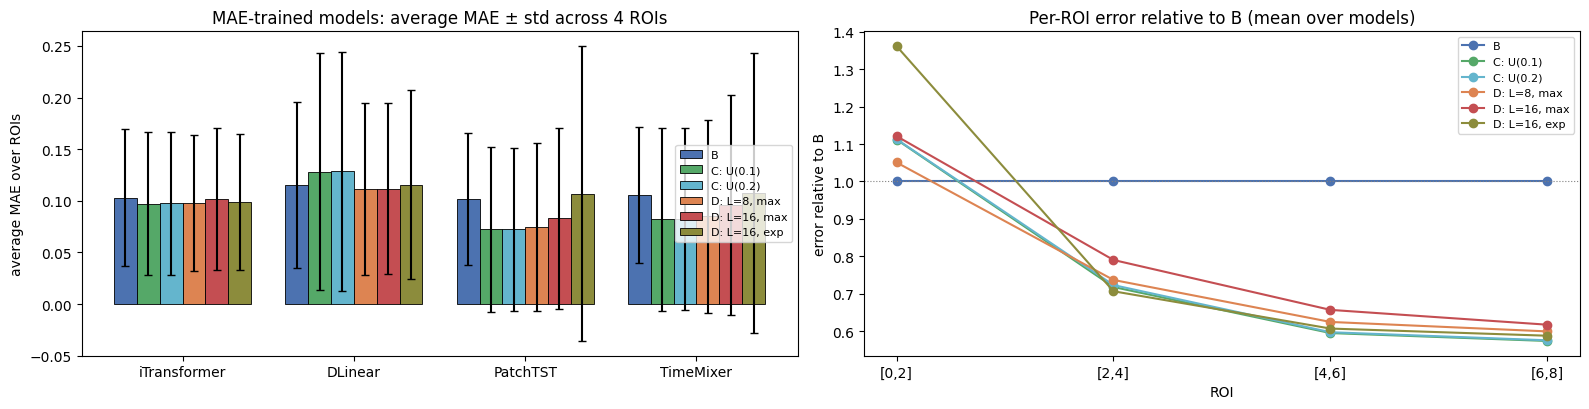

In [13]:
for loss, tab in tables.items():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.2))
    x, w = np.arange(len(MODELS)), 0.8 / len(STRATEGIES)
    for i, (lab, col) in enumerate(zip(STRAT_LABELS, STRAT_COLORS)):
        sub = tab[tab.strategy == lab].set_index("model").reindex(MODELS)
        ax1.bar(x + (i - (len(STRATEGIES) - 1) / 2) * w, sub["avg"], w, yerr=sub["std"], capsize=3,
                color=col, edgecolor="k", lw=0.6, label=lab)
    ax1.set_xticks(x, MODELS)
    ax1.set(ylabel=f"average {loss} over ROIs", title=f"{loss}-trained models: average {loss} ± std across 4 ROIs")
    ax1.legend(fontsize=8)
    base = tab[tab.strategy == "B"].set_index("model")[ROI_COLS]
    for lab, col in zip(STRAT_LABELS, STRAT_COLORS):
        rel = (tab[tab.strategy == lab].set_index("model")[ROI_COLS] / base).mean()
        ax2.plot(ROI_COLS, rel.values, marker="o", color=col, label=lab)
    ax2.axhline(1, color="gray", lw=0.8, ls=":")
    ax2.set(xlabel="ROI", ylabel="error relative to B", title="Per-ROI error relative to B (mean over models)")
    ax2.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"wireless_{loss}_bars.png"), dpi=150); plt.show()

## A7. 예측 시각화
**(a)** 가장 드문 고트래픽 ROI [6, 8]에서 B, C, D 정책의 예측을 비교합니다. ROI 값이 가장 많은 beam을 골라, test 구간 전체에 대해 `H_STEP+1` 스텝 앞 예측을 이어 붙였습니다.  
**(b)** D 정책(L=16)의 내부를 봅니다. 왼쪽은 16개 sub-interval 각각에 대한 분류 헤드의 확률이고, 오른쪽은 공식 `patch_experiments_discrete`가 ROI를 덮는 sub-interval 예측들을 `max`/`expectation`으로 합친 결과입니다. 지표에는 정답이 ROI 안에 있는 시점(금색 점)만 반영됩니다. 학습 구간 [0, 8] 안에서 값 변화가 가장 큰 (샘플, beam)을 자동으로 고릅니다.

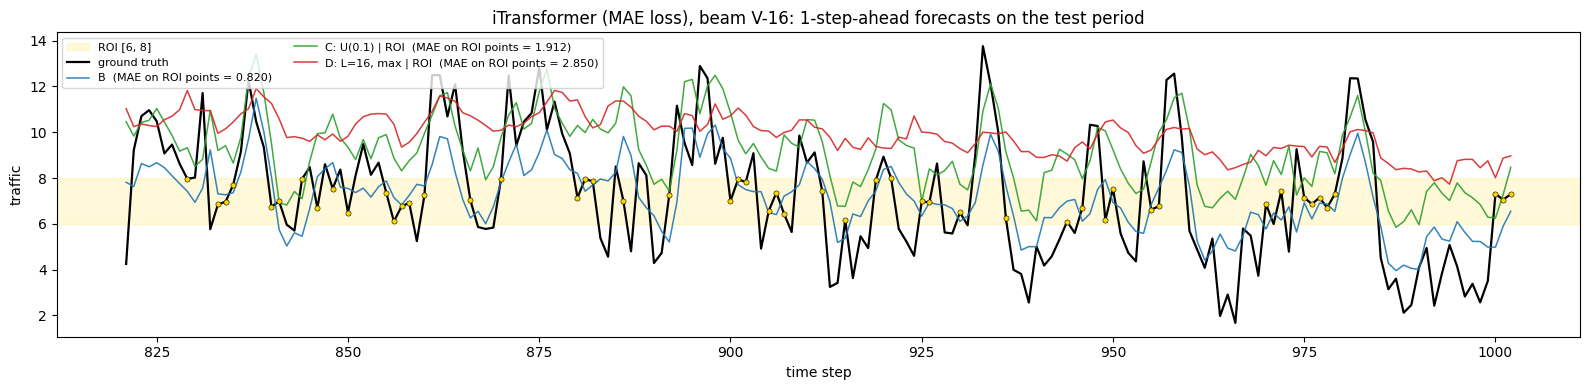

In [14]:
VIZ_MODEL, VIZ_LOSS = "iTransformer", LOSSES[0]
VIZ_ROI, H_STEP = ROIS[-1], 0
l, u = VIZ_ROI

def load_pred(name, folder):
    d = os.path.join(RES_DIR, name, folder)
    return np.load(os.path.join(d, "pred.npy")), np.load(os.path.join(d, "true.npy"))

roi_dir = f"({l}, {u})"
series = {"B": load_pred(exp_name(VIZ_MODEL, "none", VIZ_LOSS), roi_dir),
          "C: U(0.1) | ROI": load_pred(exp_name(VIZ_MODEL, "uniform", VIZ_LOSS), roi_dir),
          "D: L=16, max | ROI": load_pred(exp_name(VIZ_MODEL, "discrete8", VIZ_LOSS), roi_dir + "_max")}
true = series["B"][1]                                      # (test 샘플, pred_len, beam)
in_roi = (true >= l) & (true <= u)
v = int(np.argmax(in_roi.sum(axis=(0, 1))))                # ROI 값이 가장 많은 beam
t_abs = (T - n_te) + np.arange(true.shape[0]) + H_STEP     # 예측 대상 시점
m = in_roi[:, H_STEP, v]

fig, ax = plt.subplots(figsize=(16, 4))
ax.axhspan(l, u, color="gold", alpha=0.15, label=f"ROI [{l:g}, {u:g}]")
ax.plot(t_abs, true[:, H_STEP, v], color="k", lw=1.6, label="ground truth")
for (lab, (pred, _)), c in zip(series.items(), ["tab:blue", "tab:green", "tab:red"]):
    err = np.abs(pred[m, H_STEP, v] - true[m, H_STEP, v]).mean() if m.any() else np.nan
    ax.plot(t_abs, pred[:, H_STEP, v], color=c, lw=1.1, alpha=0.9, label=f"{lab}  (MAE on ROI points = {err:.3f})")
ax.scatter(t_abs[m], true[m, H_STEP, v], s=14, color="gold", edgecolor="k", lw=0.4, zorder=5)
ax.set(xlabel="time step", ylabel="traffic",
       title=f"{VIZ_MODEL} ({VIZ_LOSS} loss), beam {names[v]}: {H_STEP + 1}-step-ahead forecasts on the test period")
ax.legend(loc="upper left", fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "forecast_roi_high.png"), dpi=150); plt.show()

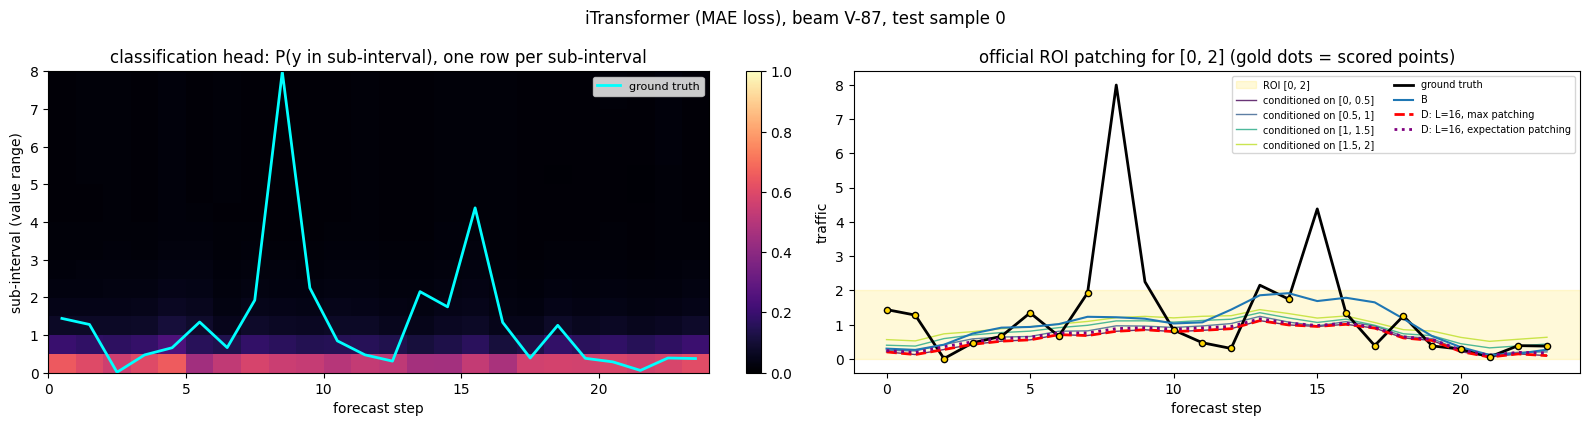

In [15]:
name = exp_name(VIZ_MODEL, "discrete8", VIZ_LOSS)
subs = separate_interval([0.0, 8.0], 16)
P = np.stack([np.load(os.path.join(RES_DIR, name, f"({a}, {b})", "pred_cls.npy")) for a, b in subs])  # (16, S, H, N)
Y = np.stack([np.load(os.path.join(RES_DIR, name, f"({a}, {b})", "pred.npy")) for a, b in subs])      # (16, S, H, N)
tmax, tmin = true.max(axis=1), true.min(axis=1)                       # (S, N)
spread = np.where(tmax <= 8, tmax - tmin, -1.0)                       # [0, 8] 안에서 가장 크게 오르내리는 (샘플, beam)
s, vb = (int(i) for i in np.unravel_index(np.argmax(spread), spread.shape))
y_true, steps = true[s, :, vb], np.arange(PRED_LEN)
lo, hi = max(ROIS, key=lambda r: int(((y_true >= r[0]) & (y_true <= r[1])).sum()))   # 이 구간 정답이 가장 많이 속한 ROI
cover = [k for k, (a, b) in enumerate(subs) if a >= lo and b <= hi]                   # ROI를 덮는 sub-interval
pick = lambda nm, folder: np.load(os.path.join(RES_DIR, nm, folder, "pred.npy"))[s, :, vb]
inr = (y_true >= lo) & (y_true <= hi)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.3))
im = ax1.imshow(P[:, s, :, vb], origin="lower", aspect="auto", extent=[0, PRED_LEN, 0, 8], cmap="magma", vmin=0, vmax=1)
ax1.plot(steps + 0.5, y_true, color="cyan", lw=2, label="ground truth")
ax1.set(xlabel="forecast step", ylabel="sub-interval (value range)", ylim=(0, 8),
        title="classification head: P(y in sub-interval), one row per sub-interval")
fig.colorbar(im, ax=ax1, fraction=0.04); ax1.legend(loc="upper right", fontsize=8)

ax2.axhspan(lo, hi, color="gold", alpha=0.15, label=f"ROI [{lo:g}, {hi:g}]")
for k, c in zip(cover, plt.cm.viridis(np.linspace(0, 0.9, len(cover)))):
    ax2.plot(steps, Y[k, s, :, vb], color=c, lw=1, alpha=0.8, label=f"conditioned on [{subs[k][0]:g}, {subs[k][1]:g}]")
ax2.plot(steps, y_true, color="k", lw=2, label="ground truth")
ax2.scatter(steps[inr], y_true[inr], s=20, color="gold", edgecolor="k", zorder=5)
ax2.plot(steps, pick(exp_name(VIZ_MODEL, "none", VIZ_LOSS), f"({lo}, {hi})"), color="tab:blue", lw=1.5, label="B")
ax2.plot(steps, pick(name, f"({lo}, {hi})_max"), color="red", lw=2, ls="--", label="D: L=16, max patching")
ax2.plot(steps, pick(name, f"({lo}, {hi})_expectation"), color="purple", lw=2, ls=":", label="D: L=16, expectation patching")
ax2.set(xlabel="forecast step", ylabel="traffic", title=f"official ROI patching for [{lo:g}, {hi:g}] (gold dots = scored points)")
ax2.legend(fontsize=7, ncol=2)
plt.suptitle(f"{VIZ_MODEL} ({VIZ_LOSS} loss), beam {names[vb]}, test sample {s}")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "interval_classification.png"), dpi=150); plt.show()

## A8. 논문 Table 1 방식으로 평가
A5–A6은 저장소 `viz.sh`처럼 폭 2인 ROI 4개로 평가했지만, 논문 Table 1의 BLW-TrafficDS 결과는 **MAE로 학습한 모델을 폭 1인 구간 8개**(I1 = [0, 1] … I8 = [7, 8])로 평가합니다.

| 논문 열 | 실험 | 평가 방법 |
|---|---|---|
| D_L | `discrete4` (L=8) | 학습한 구간 그대로 (patching 없음) |
| D¹_2L / D∞_2L | `discrete8` (L=16) | sub-interval 2개를 expectation / max로 patching |
| B | `none` | 구간 조건 없음 |
| C_0.2 | `uniform02` (`w_hat=0.2`) | 논문 표기 그대로. 저장소 `train.sh` 설정(`w_hat=0.1`)은 `C_0.1 (저장소)` 열로 따로 표시 |

평가만 다시 하므로 학습은 필요 없습니다(체크포인트가 남아 있어야 함). 아래 표와 그래프는 논문 Table 1 값(MAE ×10³)을 함께 보여줍니다. 논문 부록의 학습 설정(3층, `d_model=256`, AdamW `lr=1e-3`, 50 에폭)은 `train.sh`와 다르지만, `train.sh` 설정으로 학습한 B 정책이 논문 표와 일치하므로 이 노트북은 `train.sh`를 따릅니다.

평가할 실험 20개 (전체 20개 중)
  ✅ iTransformer_none_MAE (1s)
  ✅ iTransformer_uniform_MAE (1s)
  ✅ iTransformer_uniform02_MAE (1s)
  ✅ iTransformer_discrete4_MAE (23s)
  ✅ iTransformer_discrete8_MAE (29s)
  ✅ DLinear_none_MAE (1s)
  ✅ DLinear_uniform_MAE (1s)
  ✅ DLinear_uniform02_MAE (1s)
  ✅ DLinear_discrete4_MAE (23s)
  ✅ DLinear_discrete8_MAE (29s)
  ✅ PatchTST_none_MAE (1s)
  ✅ PatchTST_uniform_MAE (1s)
  ✅ PatchTST_uniform02_MAE (1s)
  ✅ PatchTST_discrete4_MAE (23s)
  ✅ PatchTST_discrete8_MAE (30s)
  ✅ TimeMixer_none_MAE (1s)
  ✅ TimeMixer_uniform_MAE (1s)
  ✅ TimeMixer_uniform02_MAE (1s)
  ✅ TimeMixer_discrete4_MAE (23s)
  ✅ TimeMixer_discrete8_MAE (30s)
평가: 3.6분


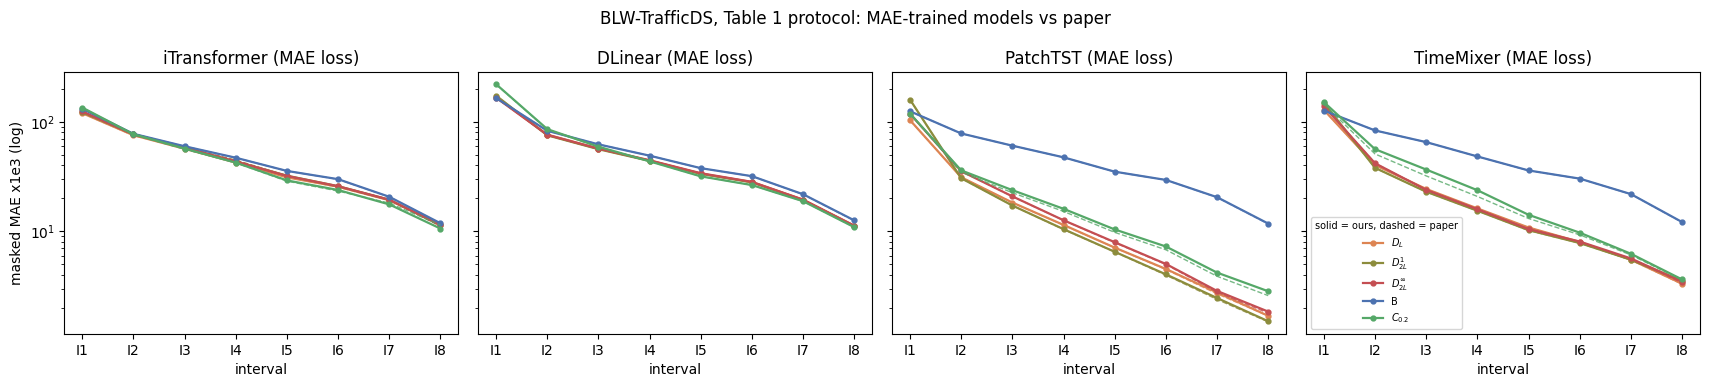

In [16]:
PAPER_ROIS = separate_interval([0.0, 8.0], 8)                 # I1 = [0, 1], …, I8 = [7, 8]
t0 = time.time()
run_eval([(exp_name(m, p, l), p) for l in LOSSES for m in MODELS for p in POLICIES], PAPER_ROIS, CKPT_DIR, RES_DIR, TAG)
print(f"평가: {(time.time() - t0) / 60:.1f}분")

# 논문 Table 1, BLW-TrafficDS (MAE ×10³, L = 8). 행 I1…I8, 열 D_L, D¹_2L, D∞_2L, B, C_0.2
PAPER_T1_BLW = {
    "DLinear":      [[167.1, 172.3, 164.9, 163.8, 218.0], [76.0, 74.9, 75.7, 82.4, 84.8], [56.7, 56.0, 56.7, 62.0, 58.8],
                     [44.2, 43.8, 44.4, 48.9, 43.4], [33.5, 33.4, 33.8, 37.6, 31.7], [28.1, 27.9, 28.2, 31.8, 26.4],
                     [19.3, 19.2, 19.4, 21.7, 18.8], [11.1, 11.1, 11.2, 12.5, 10.9]],
    "TimeMixer":    [[127.5, 148.1, 138.0, 125.9, 143.7], [40.1, 37.8, 41.7, 83.0, 50.7], [24.3, 22.9, 23.8, 64.9, 32.0],
                     [16.1, 15.4, 15.8, 48.1, 20.8], [10.8, 10.2, 10.4, 35.8, 13.1], [8.0, 7.8, 8.0, 30.2, 9.3],
                     [5.5, 5.5, 5.6, 21.8, 6.1], [3.3, 3.5, 3.4, 12.1, 3.6]],
    "PatchTST":     [[102.8, 158.2, 117.8, 124.1, 118.1], [31.1, 30.4, 35.3, 77.9, 34.6], [18.3, 17.2, 20.8, 60.3, 22.5],
                     [11.4, 10.4, 12.6, 47.2, 15.2], [7.1, 6.5, 7.9, 34.9, 9.8], [4.5, 4.0, 5.0, 29.4, 6.8],
                     [2.7, 2.4, 2.8, 20.4, 3.9], [1.7, 1.5, 1.8, 11.7, 2.6]],
    "iTransformer": [[119.3, 121.1, 122.8, 130.8, 133.1], [74.7, 75.9, 75.7, 77.3, 75.6], [57.1, 58.4, 57.6, 59.5, 56.0],
                     [44.0, 44.6, 44.1, 46.8, 42.1], [31.4, 32.1, 31.9, 35.5, 28.7], [25.2, 25.7, 25.7, 29.8, 23.3],
                     [19.2, 19.5, 19.5, 20.6, 18.1], [11.2, 11.2, 11.2, 11.8, 11.4]],
}
blw_pairs = {(loss, m): (interval_table(policy_spec(lambda p: exp_name(m, p, loss)), PAPER_ROIS, "I1–I8"),
                         paper_table(PAPER_T1_BLW[m], "I1–I8"))
             for loss in LOSSES for m in MODELS}
for (loss, m), (ours, _) in blw_pairs.items():
    ours.to_csv(os.path.join(OUT_DIR, f"table1_BLW_{m}_{loss}.csv"))
compare_summary(blw_pairs, "I1–I8", "BLW-TrafficDS: I1–I8 평균 MAE ×10³, 재현 vs 논문 Table 1 (논문은 MAE 학습)")
loss_cmp = "MAE" if "MAE" in LOSSES else LOSSES[0]
plot_vs_paper({k: v for k, v in blw_pairs.items() if k[0] == loss_cmp},
              f"BLW-TrafficDS, Table 1 protocol: {loss_cmp}-trained models vs paper", f"table1_BLW_{loss_cmp}.png")

---
# Part B. 합성 데이터 toy 예제 (README 애니메이션 재현)
`Synthetic_Dataset.ipynb`로 만든 데이터입니다. 24 스텝 동안 올라가는 반파 사인이 입력으로 나온 뒤, **4가지 미래 가설 중 하나**가 이어집니다. 각 가설은 [0, 1]을 4등분한 구간 중 하나에만 들어가 있습니다. 입력이 항상 같아서 어떤 미래가 올지 알 수 없으므로, 일반 학습(B)은 네 가설의 평균을 예측합니다. 반면 구간 조건을 받는 C/D 정책은 ROI를 바꿀 때마다 해당 가설을 따라갑니다.

학습 설정은 `scripts/multivariate_forecasting/Wireless/iTransformer_train.sh` 기준이고, 논문 Table 1에 맞춰 아래처럼 확장했습니다.
- 공통: `seq_len=48`, `pred_len=24`, `lr=1e-3`. 저장소 스크립트는 iTransformer·MSE뿐이지만, 논문처럼 **4개 모델을 MAE로** 학습합니다(`TOY_MODELS`, `TOY_LOSS`).
- 정책별 에폭: B 30, C 50(`w_hat=0.1`, 논문 C₀.₂용 `w_hat=0.2`), D 60(`decay_rate=37`, L=4 / L=8)

> Part A를 건너뛰고 이 예제만 빠르게 보고 싶다면 0–2절, A3(설정), A4·A5의 **첫 번째 셀(함수 정의)**만 실행한 뒤 여기로 오면 됩니다. CPU에서도 몇 분이면 끝납니다.

가설 4개: [0.02, 0.25], [0.27, 0.50], [0.52, 0.75], [0.77, 1.00] | 학습 데이터의 각 출력 구간과 가장 가까운 가설의 RMS 차이 평균 0.049 (≈ 노이즈 0.05)


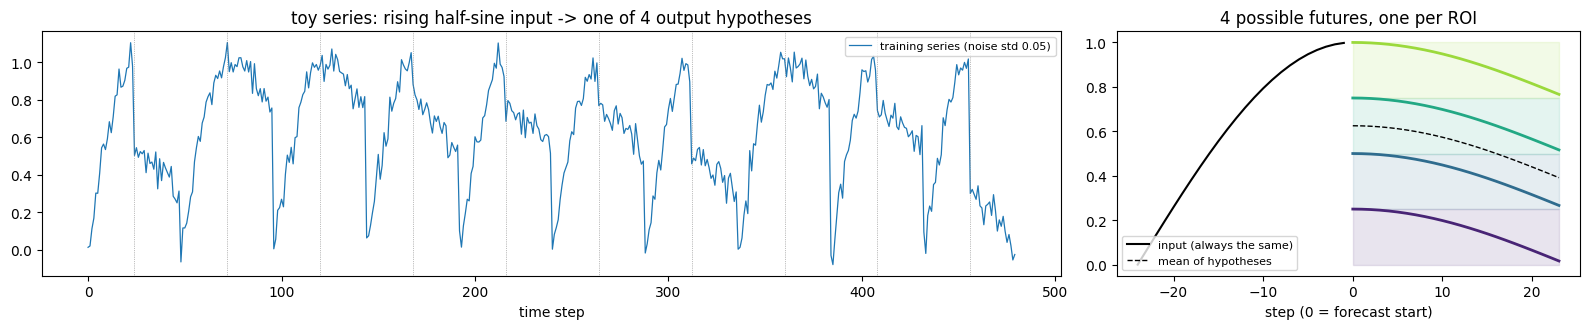

In [17]:
TOY_FILE = "toy_example_random_noise_0.05_N_1_T_3072.csv"         # iTransformer_train.sh가 쓰는 파일
TOY_SEQ, TOY_PRED = 48, 24
TOY_ROIS = [(0.0, 0.25), (0.25, 0.5), (0.5, 0.75), (0.75, 1.0)]
toy = pd.read_csv(f"dataset/wireless/{TOY_FILE}")["OT"].to_numpy()

# 4가지 미래 가설: 같은 방식으로 만든 노이즈 없는 파일에서 48 스텝 주기의 출력 구간(뒤 24 스텝)을 모아 중복 제거
# (Synthetic_Dataset.ipynb에 지금 활성화된 수식은 학습용 CSV와 달라서 데이터에서 직접 추출)
clean = pd.read_csv("dataset/wireless/toy_example_random_noise_0.0_N_1_T_3072.csv")["OT"].to_numpy()
HYPOTHESES = np.unique(clean.reshape(-1, 48)[:, 24:].round(6), axis=0)
seg = toy[: len(toy) // 48 * 48].reshape(-1, 48)[:, 24:]
rms = np.sqrt(((seg[:, None, :] - HYPOTHESES[None]) ** 2).mean(-1)).min(1)
print(f"가설 {len(HYPOTHESES)}개:", ", ".join(f"[{h.min():.2f}, {h.max():.2f}]" for h in HYPOTHESES),
      f"| 학습 데이터의 각 출력 구간과 가장 가까운 가설의 RMS 차이 평균 {rms.mean():.3f} (≈ 노이즈 0.05)")
toy_colors = plt.cm.viridis(np.linspace(0.1, 0.85, 4))
roi_index = lambda h: next(i for i, (lo, hi) in enumerate(TOY_ROIS) if lo <= h.mean() <= hi)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 3.4), gridspec_kw=dict(width_ratios=[2.2, 1]))
ax1.plot(toy[:480], lw=0.9, label="training series (noise std 0.05)")
for i in range(24, 480, 48):
    ax1.axvline(i, color="gray", lw=0.5, ls=":")
ax1.set(xlabel="time step", title="toy series: rising half-sine input -> one of 4 output hypotheses")
ax1.legend(fontsize=8)
ax2.plot(np.arange(-24, 0), np.sin(np.pi / 48 * np.arange(24)), color="k", label="input (always the same)")
for h in HYPOTHESES:
    k = roi_index(h)
    ax2.fill_between(np.arange(24), *TOY_ROIS[k], color=toy_colors[k], alpha=0.12)
    ax2.plot(np.arange(24), h, color=toy_colors[k], lw=2)
ax2.plot(np.arange(24), np.mean(HYPOTHESES, axis=0), "k--", lw=1, label="mean of hypotheses")
ax2.set(xlabel="step (0 = forecast start)", title="4 possible futures, one per ROI")
ax2.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

In [18]:
TOY_MODELS = ["iTransformer", "DLinear", "PatchTST", "TimeMixer"]   # 논문 Table 1 SynthDS (저장소 스크립트는 iTransformer만)
TOY_LOSS   = "MAE"                                                    # 논문은 MAE (저장소 iTransformer_train.sh는 기본값 MSE)
TOY_EPOCHS = lambda e: e if RUN_MODE == "full" else 3
TOY_COMMON = dict(root_path="./dataset/wireless/", data_path=TOY_FILE, data="custom", features="M",
                  seq_len=TOY_SEQ, pred_len=TOY_PRED, e_layers=2, enc_in=1, dec_in=1, c_out=1, des="Exp",
                  d_model=128, d_ff=128, itr=1, n_heads=4, batch_size=32, lradj="type3", learning_rate=1e-3,
                  dropout=0.1, num_workers=0, loss=TOY_LOSS, checkpoints=CKPT_DIR, results=RES_DIR)
TOY_POLICIES = {   # iTransformer_train.sh의 정책별 설정 + 논문 C_0.2
    "none":      dict(model_id="None", training_interval_technique="interval-none", train_epochs=TOY_EPOCHS(30)),
    "uniform":   dict(model_id="Uniform", training_interval_technique="interval-uniform", w_hat=0.1,
                      decay_rate=1e12, train_epochs=TOY_EPOCHS(50), train_interval_l=0, train_interval_u=1),
    "uniform02": dict(model_id="Uniform", training_interval_technique="interval-uniform", w_hat=0.2,
                      decay_rate=1e12, train_epochs=TOY_EPOCHS(50), train_interval_l=0, train_interval_u=1),
    "discrete4": dict(model_id="Discrete", training_interval_technique="interval-discrete", decay_rate=37,
                      nr_intervals=4, train_epochs=TOY_EPOCHS(60), train_interval_l=0, train_interval_u=1),
    "discrete8": dict(model_id="Discrete", training_interval_technique="interval-discrete", decay_rate=37,
                      nr_intervals=8, train_epochs=TOY_EPOCHS(60), train_interval_l=0, train_interval_u=1),
}
toy_name = lambda model, policy: f"toy_{model}_{policy}_{TOY_LOSS}"

toy_jobs = [(m, p) for m in TOY_MODELS for p in TOY_POLICIES]
t0 = time.time()
for i, (model, policy) in enumerate(toy_jobs, 1):
    print(f"▶ [{i}/{len(toy_jobs)}] {toy_name(model, policy)}")
    run_train(dict(TOY_COMMON, **TOY_POLICIES[policy], model=model, experiment_name=toy_name(model, policy)), CKPT_DIR, TAG)
run_eval([(toy_name(m, p), p) for m, p in toy_jobs], TOY_ROIS, CKPT_DIR, RES_DIR, TAG)
print(f"Part B 학습·평가: {(time.time() - t0) / 60:.1f}분")

▶ [1/20] toy_iTransformer_none_MAE
    ep   1/30 | Train Loss: 0.1678369 Vali Loss: 0.1315057 Test Loss: 0.1506646
    ep  10/30 | Train Loss: 0.1141166 Vali Loss: 0.1056772 Test Loss: 0.1250400
    ep  20/30 | Train Loss: 0.1052439 Vali Loss: 0.0994722 Test Loss: 0.1181233
    ep  30/30 | Train Loss: 0.1020163 Vali Loss: 0.0955139 Test Loss: 0.1150823
✅ toy_iTransformer_none_MAE (8s)
▶ [2/20] toy_iTransformer_uniform_MAE
    ep   1/50 | Train Loss: 0.0446593 Vali Loss: 0.0234455 Test Loss: 0.0258117
    ep  10/50 | Train Loss: 0.0242118 Vali Loss: 0.0142664 Test Loss: 0.0154611
    ep  20/50 | Train Loss: 0.0228956 Vali Loss: 0.0132827 Test Loss: 0.0147183
    ep  30/50 | Train Loss: 0.0221299 Vali Loss: 0.0119442 Test Loss: 0.0128181
    ep  40/50 | Train Loss: 0.0195608 Vali Loss: 0.0114361 Test Loss: 0.0120748
    ep  50/50 | Train Loss: 0.0199399 Vali Loss: 0.0109573 Test Loss: 0.0120422
✅ toy_iTransformer_uniform_MAE (14s)
▶ [3/20] toy_iTransformer_uniform02_MAE
    ep   1/50 | T

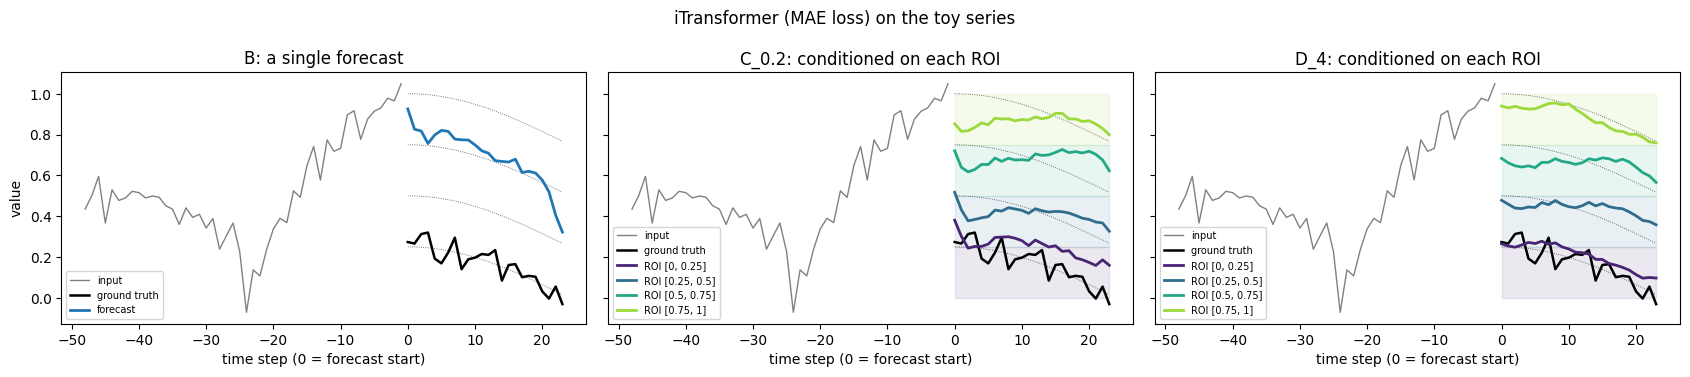

In [19]:
# 예측 구간이 '출력 가설' 구간과 정확히 겹치는 test 샘플 (데이터는 48 스텝 주기)
TOY_VIZ_MODEL = "iTransformer" if "iTransformer" in TOY_MODELS else TOY_MODELS[0]
n_te_toy = int(len(toy) * 0.2)
border1 = len(toy) - n_te_toy - TOY_SEQ                     # Dataset_Custom의 test 시작 위치
s0 = (24 - (border1 + TOY_SEQ)) % 48
TOY_SAMPLE = s0                                             # s0 + 48*k 로 바꾸면 다른 주기를 볼 수 있음

def toy_pred(policy, roi, suffix=""):
    d = os.path.join(RES_DIR, toy_name(TOY_VIZ_MODEL, policy), f"({roi[0]}, {roi[1]}){suffix}")
    return np.load(os.path.join(d, "pred.npy"))[TOY_SAMPLE, :, 0]

ctx = toy[border1 + TOY_SAMPLE: border1 + TOY_SAMPLE + TOY_SEQ]
fut = np.load(os.path.join(RES_DIR, toy_name(TOY_VIZ_MODEL, "none"), f"({TOY_ROIS[0][0]}, {TOY_ROIS[0][1]})", "true.npy"))[TOY_SAMPLE, :, 0]
xc, xf = np.arange(-TOY_SEQ, 0), np.arange(TOY_PRED)
panels = [("B: a single forecast", "none", None, ""),
          ("C_0.2: conditioned on each ROI", "uniform02", TOY_ROIS, ""),
          ("D_4: conditioned on each ROI", "discrete4", TOY_ROIS, "_max")]
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
for ax, (title, policy, rois, suf) in zip(axes, panels):
    ax.plot(xc, ctx, color="gray", lw=1, label="input")
    for h in HYPOTHESES:
        ax.plot(xf, h, color="k", lw=0.6, ls=":", alpha=0.7)
    ax.plot(xf, fut, color="k", lw=1.8, label="ground truth")
    if rois is None:
        ax.plot(xf, toy_pred(policy, TOY_ROIS[0]), color="tab:blue", lw=2, label="forecast")
    else:
        for (lo, hi), c in zip(rois, toy_colors):
            ax.fill_between(xf, lo, hi, color=c, alpha=0.1)
            ax.plot(xf, toy_pred(policy, (lo, hi), suf), color=c, lw=2, label=f"ROI [{lo:g}, {hi:g}]")
    ax.set(title=title, xlabel="time step (0 = forecast start)")
    ax.legend(fontsize=7, loc="lower left")
axes[0].set_ylabel("value")
plt.suptitle(f"{TOY_VIZ_MODEL} ({TOY_LOSS} loss) on the toy series")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "toy_forecasts.png"), dpi=150); plt.show()

### B4. 논문 SynthDS 결과(Table 1)와 비교
논문 Table 1의 SynthDS는 이 예제와 같은 구간 4개로 평가합니다(D_L은 L=4를 그대로, D⋆_2L은 L=8을 patching, MAE ×10³). 남은 차이는 데이터입니다. 저장소에 있는 3,072점 파일과 `Dataset_Custom`의 70/10/20 분할을 쓰는데(논문 3,456점·66/17/17), 논문이 쓴 원본 무작위 trace는 공개되지 않았습니다. iTransformer 외 모델의 하이퍼파라미터는 iTransformer 스크립트 값을 그대로 썼습니다.

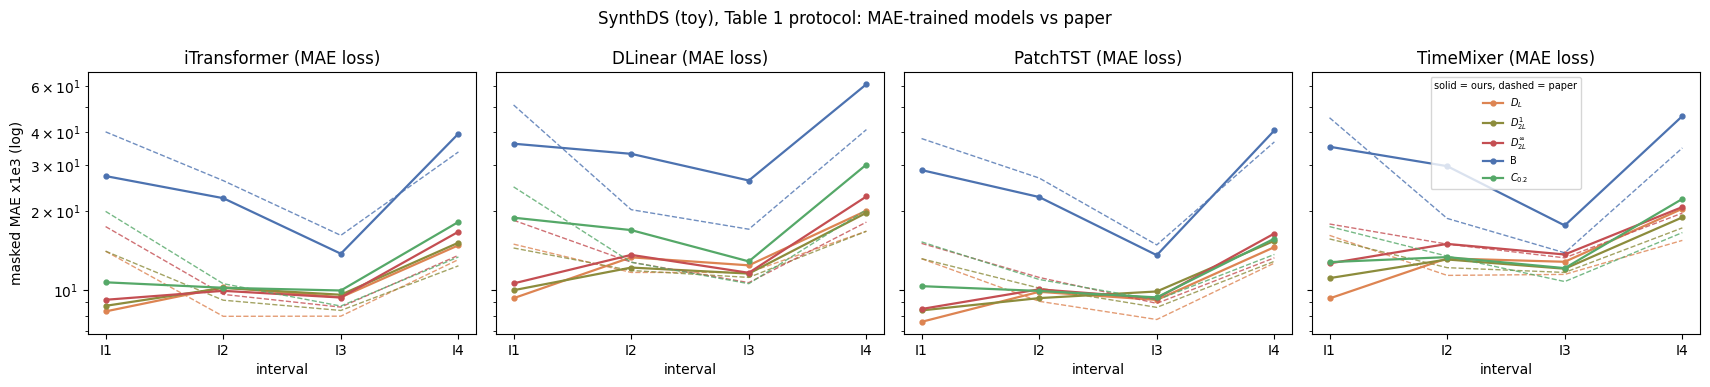

In [20]:
# 논문 Table 1, SynthDS (MAE ×10³, L = 4). 행 I1…I4, 열 D_L, D¹_2L, D∞_2L, B, C_0.2
PAPER_T1_SYNTH = {
    "DLinear":      [[15.0, 14.5, 18.5, 50.9, 24.8], [11.7, 11.9, 12.8, 20.3, 12.8], [11.7, 11.2, 10.7, 17.1, 10.6], [16.8, 16.8, 18.2, 41.0, 20.3]],
    "TimeMixer":    [[16.2, 15.7, 17.9, 45.5, 17.5], [11.4, 12.2, 15.0, 18.8, 13.5], [11.5, 11.7, 13.3, 13.9, 10.8], [15.5, 17.3, 19.7, 34.9, 16.6]],
    "PatchTST":     [[13.2, 13.2, 15.1, 37.9, 15.3], [9.08, 10.2, 11.2, 26.8, 11.0], [7.74, 8.61, 8.92, 14.9, 9.19], [12.7, 12.9, 13.3, 36.8, 13.7]],
    "iTransformer": [[14.1, 14.1, 17.5, 40.2, 20.0], [7.96, 9.17, 9.65, 26.2, 10.6], [7.97, 8.38, 8.63, 16.2, 8.71], [13.1, 12.4, 13.6, 33.7, 13.4]],
}
synth_pairs = {(TOY_LOSS, m): (interval_table(policy_spec(lambda p: toy_name(m, p)), TOY_ROIS, "I1–I4"),
                               paper_table(PAPER_T1_SYNTH[m], "I1–I4")) for m in TOY_MODELS}
for (_, m), (ours, _) in synth_pairs.items():
    ours.to_csv(os.path.join(OUT_DIR, f"table1_SynthDS_{m}_{TOY_LOSS}.csv"))
compare_summary(synth_pairs, "I1–I4", "SynthDS(toy): I1–I4 평균 MAE ×10³, 재현 vs 논문 Table 1")
plot_vs_paper(synth_pairs, f"SynthDS (toy), Table 1 protocol: {TOY_LOSS}-trained models vs paper", "table1_SynthDS.png")

---
## 결과 내려받기 (선택)
표(CSV)·그래프(PNG)·로그를 zip으로 묶습니다. `INCLUDE_ARRAYS = True`로 바꾸면 체크포인트와 예측 배열까지 포함됩니다(수 GB가 될 수 있음).

In [21]:
INCLUDE_ARRAYS = False
import zipfile
zip_path = os.path.join(BASE_DIR, f"gotsf_colab_outputs{TAG}.zip")
folders = [OUT_DIR, LOG_DIR] + ([CKPT_DIR, RES_DIR] if INCLUDE_ARRAYS else [])
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in folders:
        for root, _, files in os.walk(os.path.normpath(folder), followlinks=True):
            for f in files:
                zf.write(os.path.join(root, f))
print(f"✔ {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

✔ /content/gotsf_colab_outputs.zip (1.4 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 참고 사항
- **논문과 일치하는 정도**: A100에서 MAE로 학습한 B 정책은 논문 Table 1(BLW-TrafficDS)과 구간별로 0.2(×10⁻³) 이내로 일치했습니다. 같은 코드와 시드(2023)를 쓰므로 다른 정책도 가깝게 나올 것으로 기대되지만, GPU 비결정성과 라이브러리 버전 차이로 조금씩 달라질 수 있습니다. A8·B4의 비교표로 확인하세요.
- **학습 설정**: 논문 부록(3층, `d_model=256`, AdamW `lr=1e-3`, 50 에폭, patience 5)과 저장소 `train.sh`(2층, `d_model=128`, Adam `lr=1e-4`, 60 에폭, patience 25)가 다릅니다. `train.sh`로 학습한 B가 논문 표와 일치하므로 `train.sh`를 따릅니다. 분류 손실 가중치 ϕ는 논문에 값이 없어서 코드 기본값 0.1을 씁니다.
- **SynthDS의 남은 차이**: 저장소의 3,072점 파일과 70/10/20 분할을 씁니다(논문 3,456점·66/17/17). 원본 무작위 trace는 공개되지 않아 똑같이 만들 수 없습니다.
- **포함하지 않은 실험**: Table 1의 Traffic·Electricity·Weather, E2E 정책(Fig. 2a), 부록의 하이퍼파라미터 민감도(Fig. 6–9)와 에너지 절감 실험(Fig. 5)은 저장소에 실행 스크립트가 없어 이 노트북에 없습니다. 저장소의 ETT·ECL·Traffic 스크립트는 iTransformer 원본에서 온 것으로, 저장소에 없는 `run.py`를 호출합니다.
- **지표 해석**: 마스크를 곱한 뒤 전체 원소로 평균하므로, 해당 구간에 속한 값이 적을수록 지표가 작아집니다. 구간끼리 절대값을 비교하기보다 같은 구간 안에서 정책끼리 비교하세요.
- **이름 주의**: `train.sh`의 `discrete4`/`discrete8`은 실제로 `nr_intervals=8`/`16`(논문의 D_8, D_16)입니다. `uniform02`는 이 노트북에서 추가한 논문 C₀.₂ 설정입니다.
- **구간 분류 헤드 관찰**: iTransformer는 분류 확률이 실제 값보다 데이터 전체에서 흔한 낮은 구간 쪽에 몰리는 경향이 있습니다. 변수별 정규화(`use_norm`)를 거친 입력으로 분류 헤드를 계산해서 각 beam의 절대 크기를 보기 어려운 구조이기 때문으로 보입니다(A7-b 왼쪽 그림).
- **재실행**: `SKIP_IF_DONE = True`이면 끝난 학습·평가는 건너뜁니다. 처음부터 다시 하려면 `checkpoints*/`, `results*/` 폴더를 지우세요.